# PYNQ-Z2 FPGA 边缘检测与车牌抓拍

1. 初始化 FPGA
2. ARM / FPGA 结果与耗时对比
3. 摄像头采集、ROI 保存与车牌识别

在 **PYNQ 板端 Jupyter** 从上往下逐格运行。先停止板端视频服务，避免摄像头和 DMA 被占用。

## 1. 参数与模块导入

`PC_IP` 填电脑地址，`CAMERA_INDEX` 填板端摄像头编号。其余路径自动从当前目录查找。

In [1]:
from pathlib import Path
from datetime import datetime
from IPython.display import HTML, display
import base64
import html
import json
import sys
import time
import urllib.request

import cv2
import numpy as np

PC_IP = '192.168.2.1'
CAMERA_INDEX = 0

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, cwd.parent, cwd.parent.parent)
             if (p / 'edge_dma_runtime.py').is_file()), None)
assert ROOT is not None, '请从交付目录的 board_check/ 中打开本 Notebook'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from edge_dma_runtime import EdgeDmaRuntime
import opencv_benchmark as reference
import pynq_video_server as server
assert callable(server.valid_roi) and callable(server.save_roi), '板端 ROI 服务功能不完整'

SAVE_DIR = ROOT / 'board_check' / 'results' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print('项目目录：', ROOT)
print('图片保存目录：', SAVE_DIR)

项目目录： /home/xilinx/jupyter_notebooks/fpga_edge_vision
图片保存目录： /home/xilinx/jupyter_notebooks/fpga_edge_vision/board_check/results/20250504_121905_911233


In [2]:
# 并排显示图像，不需要额外安装绘图库
def show_images(*images):
    blocks = []
    for title, image in images:
        ok, encoded = cv2.imencode('.png', image)
        assert ok, '图像编码失败'
        data = base64.b64encode(encoded).decode('ascii')
        blocks.append('<figure style="margin:8px;flex:1;min-width:200px">'
                      '<img style="width:100%" src="data:image/png;base64,' + data + '">'
                      '<figcaption>' + html.escape(title) + '</figcaption></figure>')
    display(HTML('<div style="display:flex;flex-wrap:wrap">' + ''.join(blocks) + '</div>'))

## 2. 加载 FPGA

加载交付的 `sobel_edge.bit/.hwh`，初始化 ROI 和边缘图两路 DMA。出现“已就绪”后继续。

In [3]:
if globals().get('runtime') is not None:
    runtime.close()
runtime = EdgeDmaRuntime(ROOT, timeout_s=3.0)
runtime.print_status('FPGA 已就绪')

加载Overlay: /home/xilinx/jupyter_notebooks/fpga_edge_vision/sobel_edge.bit


双DMA已就绪
FPGA 已就绪
  main_mm2s_dmasr = 0x00000000
  main_s2mm_dmasr = 0x00000000
  edge_s2mm_dmasr = 0x00000000


## 3. ARM / FPGA 对比

将三组标准图像送入 FPGA，并与 ARM OpenCV、预期结果对比。应看到六字段一致、边缘误差为 0。
六字段依次为：`x, y, w, h, 最大连通域网格数, 缩减率×100`。耗时取本次运行值。


--- single_target ---
FPGA： [160, 160, 160, 160, 4, 9167]  ARM： [160, 160, 160, 160, 4, 9167]  边缘误差： 0
FPGA 完整调用 12.796 ms | DMA 窗口 8.651 ms | ARM 211.467 ms | ARM/FPGA 16.53x



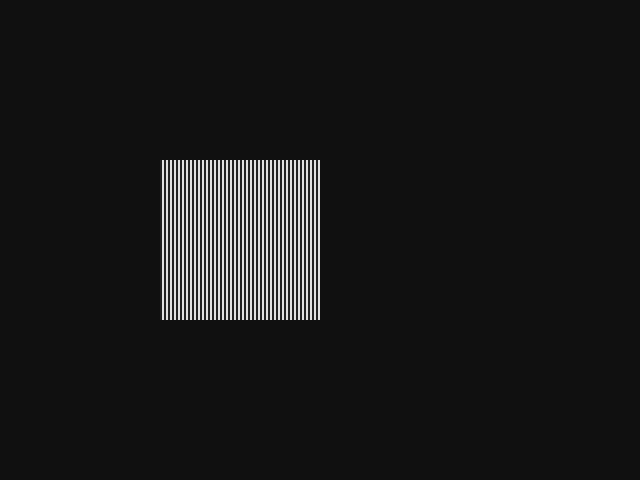
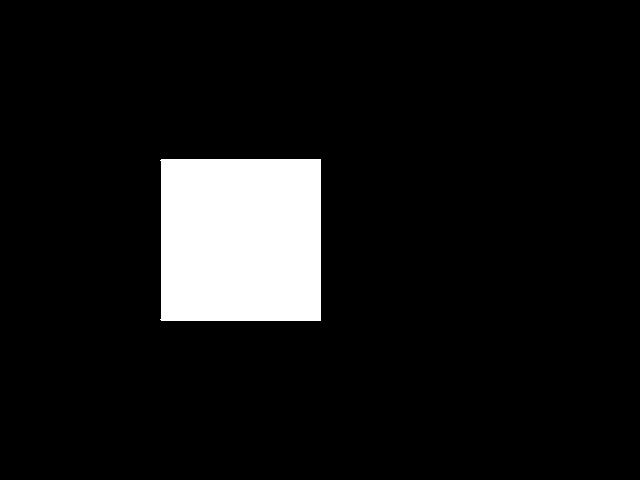
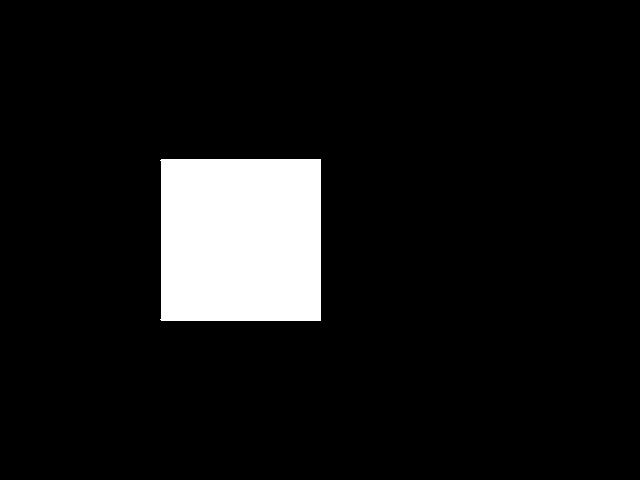


--- multi_target ---
FPGA： [80, 80, 240, 160, 6, 8750]  ARM： [80, 80, 240, 160, 6, 8750]  边缘误差： 0
FPGA 完整调用 11.856 ms | DMA 窗口 8.569 ms | ARM 129.433 ms | ARM/FPGA 10.92x



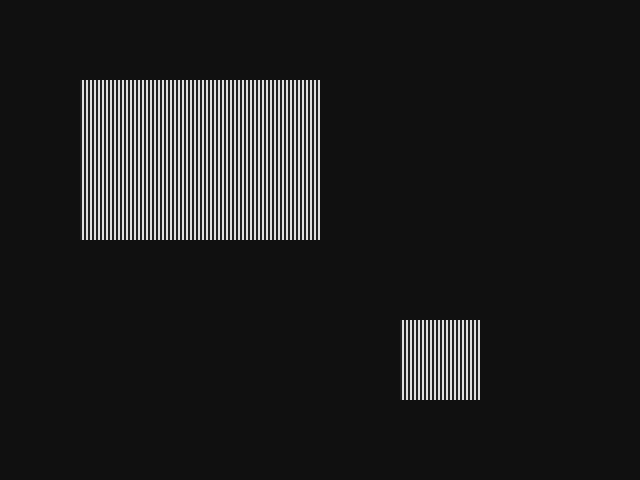
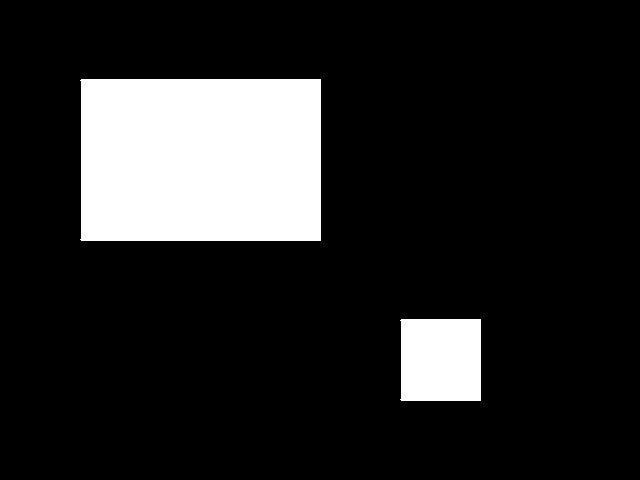
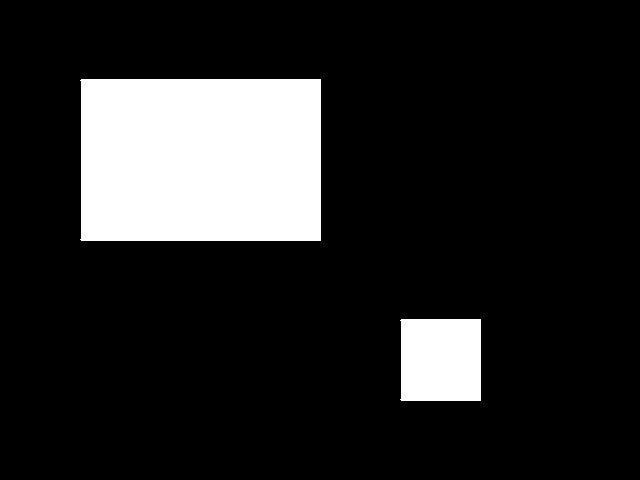


--- noise_target ---
FPGA： [400, 160, 160, 160, 4, 9167]  ARM： [400, 160, 160, 160, 4, 9167]  边缘误差： 0
FPGA 完整调用 11.913 ms | DMA 窗口 8.677 ms | ARM 129.232 ms | ARM/FPGA 10.85x



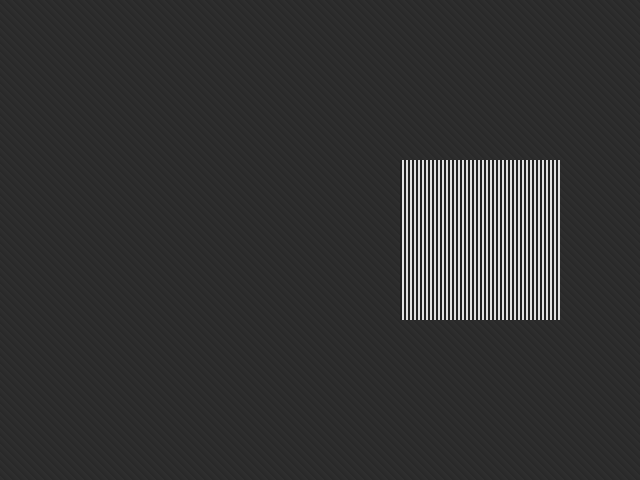
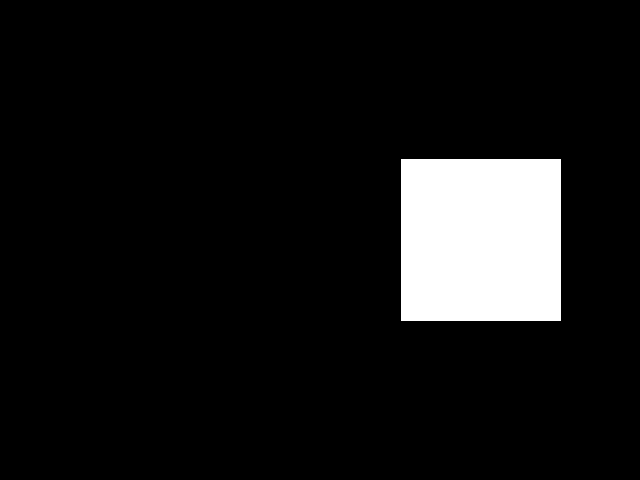
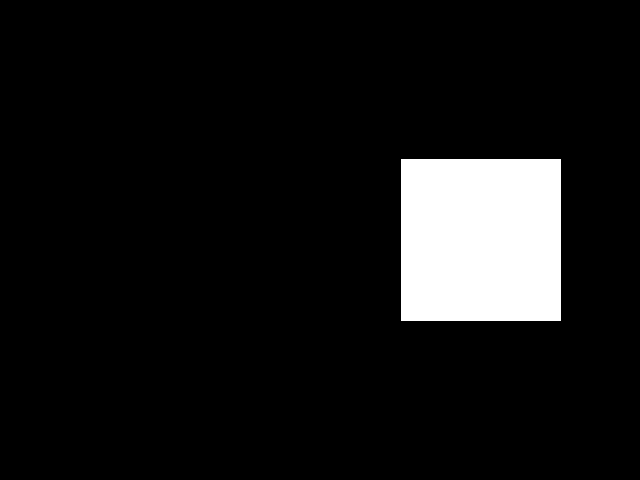

FPGA： [0, 0, 0, 0, 0, 10000]  ARM： [0, 0, 0, 0, 0, 10000]  边缘误差： 0
FPGA 完整调用 11.535 ms | DMA 窗口 8.132 ms | ARM 132.499 ms | ARM/FPGA 11.49x
三组标准图像和空白帧均一致。


In [4]:
def compare_frame(gray):
    try:
        started = time.perf_counter()
        fields, edge, dma_ms = runtime.run_gray(gray)
        fpga_ms = (time.perf_counter() - started) * 1000
    except (Exception, KeyboardInterrupt):
        runtime.close()
        raise

    started = time.perf_counter()
    arm = reference.opencv_roi_pipeline(gray)
    arm_fields = reference.result_fields(arm)
    arm_ms = (time.perf_counter() - started) * 1000
    errors = int(np.count_nonzero(edge != arm['edge']))
    print('FPGA：', fields, ' ARM：', arm_fields, ' 边缘误差：', errors)
    print('FPGA 完整调用 {:.3f} ms | DMA 窗口 {:.3f} ms | ARM {:.3f} ms | ARM/FPGA {:.2f}x'
          .format(fpga_ms, dma_ms, arm_ms, arm_ms / fpga_ms))
    assert fields == arm_fields and errors == 0, 'ARM / FPGA 结果不一致'
    return fields, edge, arm['edge']

cases = [('single_target', [160, 160, 160, 160, 4, 9167]),
         ('multi_target', [80, 80, 240, 160, 6, 8750]),
         ('noise_target', [400, 160, 160, 160, 4, 9167])]

for name, expected_fields in cases:
    gray = np.fromfile(str(ROOT / 'validation' / (name + '_640x480_input.bin')),
                       dtype=np.uint8).reshape(480, 640)
    magnitude = np.fromfile(str(ROOT / 'validation' / (name + '_640x480_expected.bin')),
                            dtype=np.uint8).reshape(480, 640)
    expected_edge = np.where(magnitude >= 80, 255, 0).astype(np.uint8)
    print('\n---', name, '---')
    fields, edge, arm_edge = compare_frame(gray)
    assert fields == expected_fields and np.array_equal(edge, expected_edge), '与标准结果不一致'
    show_images(('输入图像', gray), ('FPGA 边缘', edge), ('ARM 边缘', arm_edge))

blank = np.zeros((480, 640), dtype=np.uint8)
fields, edge, _ = compare_frame(blank)
assert fields == [0, 0, 0, 0, 0, 10000] and not np.any(edge)
print('三组标准图像和空白帧均一致。')

## 4. 摄像头采集与同帧对比

把清晰车牌放入画面，运行下格。应显示彩色原图、ROI 框与 FPGA 边缘图。
没有有效 ROI 时，调整目标位置后重跑本格；要求摄像头输出原生 `640×480`。

[ WARN:0] global ./modules/videoio/src/cap_gstreamer.cpp (616) isPipelinePlaying OpenCV | GStreamer warning: GStreamer: pipeline have not been created


FPGA： [80, 0, 480, 160, 9, 7500]  ARM： [80, 0, 480, 160, 9, 7500]  边缘误差： 0
FPGA 完整调用 10.917 ms | DMA 窗口 8.617 ms | ARM 126.983 ms | ARM/FPGA 11.63x



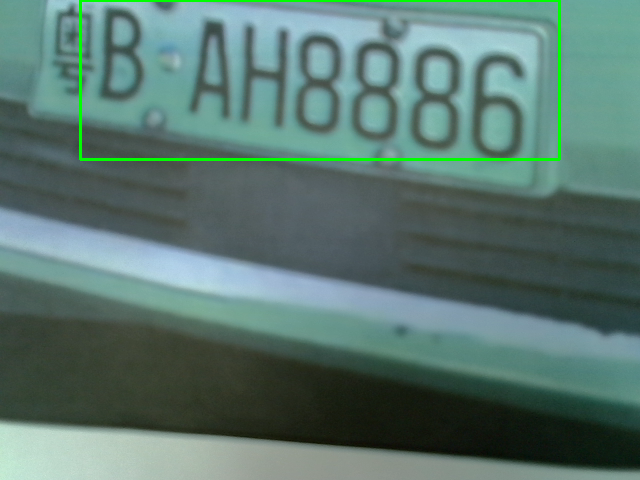
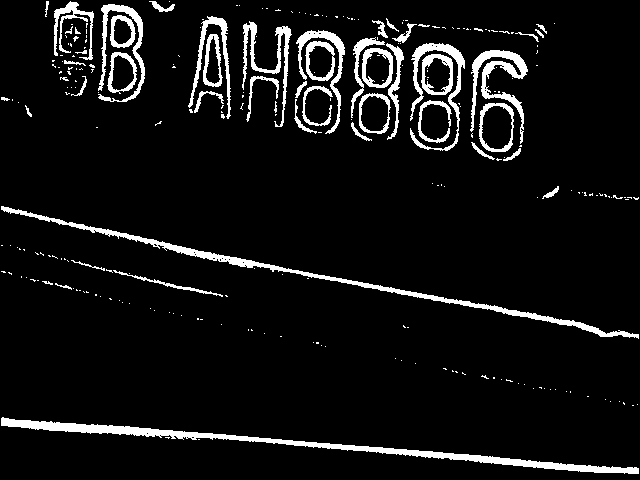

In [16]:
frame = None
roi_path = None
cap = cv2.VideoCapture(CAMERA_INDEX)
try:
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
    cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
    assert cap.isOpened(), '摄像头打不开，请检查 USB Host、编号及占用程序'
    for _ in range(5):
        ok, frame = cap.read()
        assert ok and frame is not None, '摄像头读帧失败'
finally:
    cap.release()

assert frame.shape == (480, 640, 3) and frame.dtype == np.uint8, '需要 640×480 BGR 图像'
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
fields, edge, _ = compare_frame(gray)
preview = frame.copy()
if server.valid_roi(fields):
    x, y, w, h = fields[:4]
    cv2.rectangle(preview, (x, y), (x + w - 1, y + h - 1), (0, 255, 0), 2)
else:
    print('当前没有有效 ROI，请调整目标后重跑本格。')
show_images(('摄像头与 ROI', preview), ('FPGA 边缘', edge))

## 5. 保存彩色 ROI

保存的是未画框的原始彩色裁剪图。查看下面图片，确认车牌完整、清晰。

已保存： /home/xilinx/jupyter_notebooks/fpga_edge_vision/board_check/results/20250504_121905_911233/roi_20250504_122044_357970.jpg



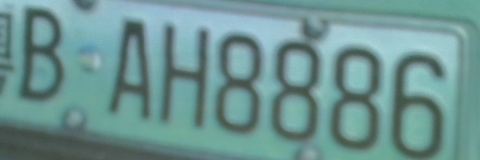

In [17]:
roi_path = None
assert frame is not None and server.valid_roi(fields), '先调整目标，重新运行第 4 步'
roi_path = server.save_roi(frame, fields, SAVE_DIR)
crop = cv2.imread(str(roi_path))
x, y, w, h = fields[:4]
assert crop is not None and crop.shape == (h, w, 3), '保存的 ROI 尺寸异常'
print('已保存：', roi_path)
show_images(('彩色 ROI', crop))

## 6. 连接电脑识别服务

先在电脑的 `src/plate_lpr_server/` 打开 CMD，按本目录 README 创建环境并运行 `prepare_models.py`，再执行 `venv\Scripts\python.exe server.py`。
运行下格，JSON 的 `status` 应为 `ok`，`auto_save_policy` 为 `plate-confirmed-v2`，与当前板端自动保存策略匹配。

In [18]:
AI_BASE = 'http://{}:5000'.format(PC_IP)
http = urllib.request.build_opener(urllib.request.ProxyHandler({}))
with http.open(AI_BASE + '/health', timeout=3.0) as response:
    health = json.loads(response.read().decode('utf-8'))
print(health)
assert health.get('status') == 'ok', '电脑识别服务未就绪'

{'auto_save_policy': 'plate-confirmed-v2', 'status': 'ok'}


## 7. 识别当前 ROI

把刚保存的图片发给电脑。请将返回号码与实际车牌核对；未识别时调整清晰度，重跑第 4、5、7 步。

In [19]:
assert roi_path is not None and roi_path.is_file(), '先完成第 5 步'
request = urllib.request.Request(
    AI_BASE + '/api/recognize', data=roi_path.read_bytes(),
    headers={'Content-Type': 'image/jpeg'}, method='POST')
started = time.perf_counter()
with http.open(request, timeout=3.0) as response:
    result = json.loads(response.read().decode('utf-8'))
print('接口返回：', result)
print('请求总耗时：{:.1f} ms'.format((time.perf_counter() - started) * 1000))
assert result.get('status') in ('success', 'fail'), '识别接口返回格式异常'
if result['status'] == 'success':
    print('车牌：', result['plate'], ' 置信分数：', result['confidence'])
else:
    print('当前图片未识别出车牌，请检查上面的 ROI 图片后重新采集。')

接口返回： {'auto_save_allowed': True, 'confidence': 0.9361, 'plate': '粤BAH8886', 'status': 'success', 'time_ms': 16.0}
请求总耗时：27.0 ms
车牌： 粤BAH8886  置信分数： 0.9361


## 8. 释放硬件

运行下格后，保存 Notebook 并 **Shutdown Kernel**，再启动完整视频链路。
DMA 超时需要重启整块板子。

In [20]:
if globals().get('runtime') is not None:
    runtime.close()
    runtime = None
print('下一步：关闭本内核，在板端终端运行以下命令。')
print('cd "{}"'.format(ROOT))
print('sudo -E python3 pynq_video_server.py --pc-ip {} --camera {}'.format(PC_IP, CAMERA_INDEX))

下一步：关闭本内核，在板端终端运行以下命令。
cd "/home/xilinx/jupyter_notebooks/fpga_edge_vision"
sudo -E python3 pynq_video_server.py --pc-ip 192.168.2.1 --camera 0


## 9. 运行完整视频链路

先完成第 8 节释放硬件，保存 Notebook 并 **Shutdown Kernel**。电脑识别服务保持运行。在板端 Jupyter 打开 Terminal，进入第 1 节打印的“项目目录”；本项目的部署目录示例为：

```bash
cd /home/xilinx/jupyter_notebooks/fpga_edge_vision
sudo -E python3 validation/edge_return_test.py
```

三组均为 `PASS` 且最后显示 `ALL PASS` 后，执行第 8 节打印的视频服务命令，例如：

```bash
sudo -E python3 pynq_video_server.py --pc-ip 192.168.2.1 --camera 0
```

板端路径、电脑 IPv4 和摄像头编号以实际配置及第 8 节打印值为准。出现“等待电脑连接”后，用资源管理器打开**当前这份电脑项目的 `src/plate_lpr_server/`**，在地址栏输入 `cmd`，另开 CMD 执行：

```bat
venv\Scripts\python.exe "..\fpga_edge_vision\software\pc\pc_dashboard.py" --host 192.168.2.99
```

这里共用 `src/plate_lpr_server/venv/`。`--host` 和界面地址填写板子实际 IPv4；板端 `--pc-ip` 和 Notebook `PC_IP` 填电脑 IPv4。点击“连接 PYNQ”，先看双画面，再试手动抓拍、ARM 对照和自动抓拍。

Notebook 第 5、7 节是手动保存后识别。实时服务的手动抓拍先保存 `roi_*.jpg` 再异步识别；自动抓拍稳定累计约 1 秒后先识别，仅当识别成功、返回非空车牌且 `auto_save_allowed=true` 时保存 `auto_roi_*.jpg`，失败或超时不保存自动候选，任务结束后冷却约 4 秒。图片默认保存在板端视频脚本所在目录。

结束时关闭电脑界面，在板端视频服务和电脑识别服务终端各按 `Ctrl+C`。
